# Machine Learning Project to Predict F1 Pit Stops

In this project, I use the data from the Kaggle competition "Predicting F1 Pit Stops" (https://www.kaggle.com/competitions/playground-series-s6e5) to predict whether or not a Formula 1 driver will pit on the next lap. I explore three different models: a decision tree, a random forest classifier and a XGBoost model. I tune these three models and, in the end, choose the one with the best ROC-AUC score on the validation dataset.

## Import Libraries and Load the Data

Import NumPy, pandas, scikit-learn, tqdm and XGBoost, load the dataset and inspect the first rows.

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier

from tqdm import tqdm

import xgboost as xgb

In [2]:
print("XGBoost:", xgb.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

XGBoost: 3.4.1
Scikit-learn: 1.6.1
Pandas: 2.2.3
NumPy: 2.2.6


In [3]:
df = pd.read_csv('train.csv')
len(df)

439140

In [4]:
df.head()

,id,Driver,Compound,Race,Year,PitStop,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,RaceProgress,Position_Change,PitNextLap
0,0,D109,HARD,Canadian Grand Prix,2022,0,50,2,39.0,8,78.491,-7.564,21.019,0.714286,5.0,1.0
1,1,D086,HARD,Dutch Grand Prix,2025,1,27,2,7.0,4,75.095,-32.617,-223.207,0.346154,-3.0,0.0
2,2,ZON,HARD,Austrian Grand Prix,2022,0,59,3,22.0,13,70.945,-7.540,-100.529,0.819444,3.0,1.0
3,3,SPE,MEDIUM,Pre-Season Testing,2023,0,2,1,2.0,7,94.361,-7.324,-7.324,0.076923,0.0,0.0
4,4,D019,HARD,Azerbaijan Grand Prix,2022,1,26,3,6.0,2,107.878,8.965,-14.139,0.361111,3.0,0.0


## Data Exploration and Preparation

Uniformize the column names and the categorical entries of the data, check missing values, inspect descriptive statistics, plot some of the variables and explore the linear correlation of the numerical variables with the target variable.

In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

string_columns = list(df.dtypes[df.dtypes == 'object'].index)

for col in string_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')

del df['id']

In [6]:
df.head()

,driver,compound,race,year,pitstop,lapnumber,stint,tyrelife,position,laptime_(s),laptime_delta,cumulative_degradation,raceprogress,position_change,pitnextlap
0,d109,hard,canadian_grand_prix,2022,0,50,2,39.0,8,78.491,-7.564,21.019,0.714286,5.0,1.0
1,d086,hard,dutch_grand_prix,2025,1,27,2,7.0,4,75.095,-32.617,-223.207,0.346154,-3.0,0.0
2,zon,hard,austrian_grand_prix,2022,0,59,3,22.0,13,70.945,-7.540,-100.529,0.819444,3.0,1.0
3,spe,medium,pre-season_testing,2023,0,2,1,2.0,7,94.361,-7.324,-7.324,0.076923,0.0,0.0
4,d019,hard,azerbaijan_grand_prix,2022,1,26,3,6.0,2,107.878,8.965,-14.139,0.361111,3.0,0.0


In [7]:
df.isnull().sum()

driver                    0
compound                  0
race                      0
year                      0
pitstop                   0
lapnumber                 0
stint                     0
tyrelife                  0
position                  0
laptime_(s)               0
laptime_delta             0
cumulative_degradation    0
raceprogress              0
position_change           0
pitnextlap                0
dtype: int64

In [8]:
df.describe()

,year,pitstop,lapnumber,stint,tyrelife,position,laptime_(s),laptime_delta,cumulative_degradation,raceprogress,position_change,pitnextlap
count,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000
mean,2023.523544,0.136118,23.105909,1.789113,14.158231,9.630339,90.948735,-3.770040,-25.721759,0.337661,0.101542,0.198982
std,1.024930,0.342915,16.958261,0.950194,9.801338,5.278770,19.772769,43.945759,54.766573,0.253277,4.006765,0.399235
min,2022.000000,0.000000,1.000000,1.000000,1.000000,1.000000,67.694000,-2403.895000,-274.564000,0.012821,-18.000000,0.000000
25%,2023.000000,0.000000,9.000000,1.000000,6.000000,5.000000,82.621000,-8.884000,-46.566250,0.129870,-1.000000,0.000000
50%,2024.000000,0.000000,19.000000,2.000000,12.000000,10.000000,90.521000,-0.295000,-20.994000,0.269231,0.000000,0.000000
75%,2024.000000,0.000000,36.000000,2.000000,20.000000,14.000000,98.471000,0.115000,-6.199000,0.513158,2.000000,0.000000
max,2025.000000,1.000000,78.000000,8.000000,77.000000,20.000000,2507.607000,2423.932000,2412.026000,1.000000,18.000000,1.000000


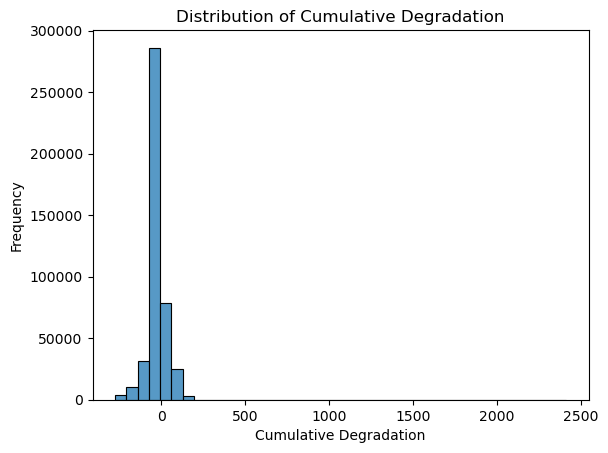

In [9]:
sns.histplot(df.cumulative_degradation, bins = 40)
plt.ylabel('Frequency')
plt.xlabel('Cumulative Degradation')
plt.title('Distribution of Cumulative Degradation')

plt.show()

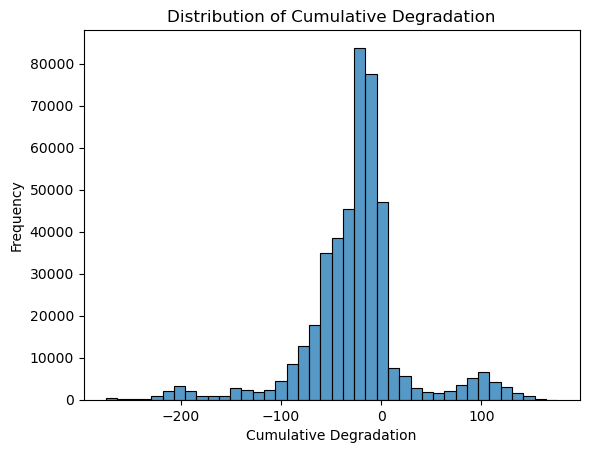

In [10]:
sns.histplot(df.loc[df['cumulative_degradation'] < 500, 'cumulative_degradation'], bins = 40)
plt.ylabel('Frequency')
plt.xlabel('Cumulative Degradation')
plt.title('Distribution of Cumulative Degradation')

plt.show()

In [11]:
df.pitnextlap.value_counts()

pitnextlap
0.0    351759
1.0     87381
Name: count, dtype: int64

This dataset is unbalanced. More than 80% of the instances have `pitnextlap=0`.

In [12]:
df[df.pitstop == 0].pitnextlap.mean()

np.float64(0.1912854375074137)

In [13]:
df[df.pitstop == 1].pitnextlap.mean()

np.float64(0.2478293601003764)

The probability of pitting on the next lap is higher for observations with `pitstop = 1` (24.8%) than for those with `pitstop = 0` (19.1%).

In [14]:
df.drop(columns='pitnextlap').corrwith(df.pitnextlap,numeric_only=True)

year                      0.125267
pitstop                   0.048567
lapnumber                 0.267057
stint                     0.198193
tyrelife                  0.273510
position                  0.021348
laptime_(s)              -0.034096
laptime_delta            -0.004946
cumulative_degradation   -0.167401
raceprogress              0.185477
position_change           0.046230
dtype: float64

The two features with strongest linear correlations with the target variable are `tyrelife` and `lapnumber`.

## Split the Data

Split the data into training and validation.

In [15]:
df_train, df_val = train_test_split(df, test_size=0.2, random_state=25)

In [16]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

In [17]:
y_train = df_train['pitnextlap'].astype('int').values
y_val = df_val['pitnextlap'].astype('int').values

In [18]:
del df_train['pitnextlap']
del df_val['pitnextlap']

## Decision Tree

Train a decision tree and tune the maximum depth and the minimum number of samples at a leaf node.

In [19]:
train_dicts = df_train.to_dict(orient='records')

In [20]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

In [21]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

DecisionTreeClassifier()

In [22]:
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [23]:
y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

np.float64(0.7802562405795999)

In [24]:
y_pred = dt.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred)

np.float64(1.0)

The model is overfitting. Let's tune the maximum depth.

In [25]:
depths = [6, 8, 10, 12, 14, 16, 18, 20, 22, None]

for depth in depths: 
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    print('%4s -> %.3f' % (depth, auc))

   6 -> 0.909


   8 -> 0.917


  10 -> 0.920


  12 -> 0.917


  14 -> 0.907


  16 -> 0.891


  18 -> 0.870


  20 -> 0.845


  22 -> 0.823


None -> 0.782


Now let's also tune the minimum number of samples at a leaf node.

In [26]:
scores = []

for depth in tqdm([8, 12, 15, 18, 20, 21, 22, 23, 24]):
    for s in [10, 50, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append((depth, s, auc))

  0%|                                                                                            | 0/9 [00:00<?, ?it/s]

 11%|█████████▎                                                                          | 1/9 [01:16<10:15, 76.91s/it]

 22%|██████████████████▋                                                                 | 2/9 [02:56<10:31, 90.15s/it]

 33%|███████████████████████████▋                                                       | 3/9 [04:48<10:00, 100.13s/it]

 44%|████████████████████████████████████▉                                              | 4/9 [06:49<09:01, 108.25s/it]

 56%|██████████████████████████████████████████████                                     | 5/9 [08:54<07:37, 114.37s/it]

 67%|███████████████████████████████████████████████████████▎                           | 6/9 [11:01<05:55, 118.66s/it]

 78%|████████████████████████████████████████████████████████████████▌                  | 7/9 [13:10<04:03, 121.97s/it]

 89%|█████████████████████████████████████████████████████████████████████████▊         | 8/9 [15:19<02:04, 124.50s/it]

100%|███████████████████████████████████████████████████████████████████████████████████| 9/9 [17:31<00:00, 126.58s/it]

100%|███████████████████████████████████████████████████████████████████████████████████| 9/9 [17:31<00:00, 116.79s/it]

In [27]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

In [28]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(4)

auc                                                  \
max_depth             8       12      15      18      20      21      22   
min_samples_leaf                                                           
10                0.9169  0.9197  0.9123  0.9007  0.8962  0.8924  0.8910   
50                0.9173  0.9251  0.9264  0.9262  0.9259  0.9257  0.9257   
100               0.9175  0.9261  0.9279  0.9287  0.9286  0.9286  0.9288   
200               0.9171  0.9257  0.9275  0.9284  0.9283  0.9284  0.9284   
500               0.9179  0.9233  0.9241  0.9244  0.9246  0.9245  0.9246   

                                  
max_depth             23      24  
min_samples_leaf                  
10                0.8891  0.8871  
50                0.9251  0.9251  
100               0.9287  0.9286  
200               0.9285  0.9285  
500               0.9246  0.9246

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

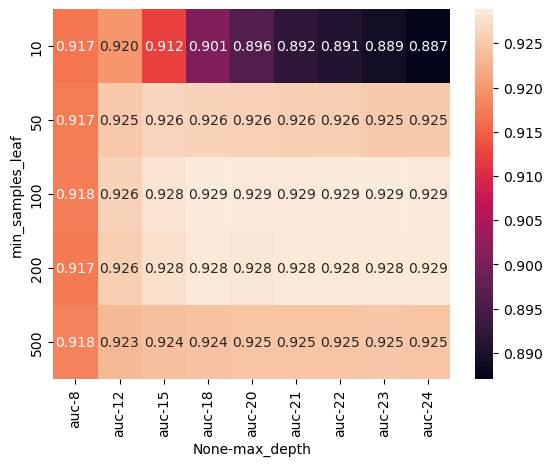

In [29]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

The best score is obtained for `max_depth=22` and `min_samples_leaf=100`.

## Random Forest Classifier

Train a random forest classifier and tune the maximum depth and the minimum number of samples at a leaf node.

In [30]:
scores = []

for n in tqdm(range(10, 101, 10)):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    scores.append((n, auc))

  0%|                                                                                           | 0/10 [00:00<?, ?it/s]

 10%|████████▎                                                                          | 1/10 [00:17<02:34, 17.12s/it]

 20%|████████████████▌                                                                  | 2/10 [00:50<03:32, 26.60s/it]

 30%|████████████████████████▉                                                          | 3/10 [01:40<04:21, 37.32s/it]

 40%|█████████████████████████████████▏                                                 | 4/10 [02:47<04:54, 49.01s/it]

 50%|█████████████████████████████████████████▌                                         | 5/10 [04:11<05:07, 61.53s/it]

... (2 outputs left out)

 80%|█████████████████████████████████████████████████████████████████▌                | 8/10 [10:02<03:25, 102.97s/it]

 90%|█████████████████████████████████████████████████████████████████████████▊        | 9/10 [12:35<01:58, 118.57s/it]

100%|█████████████████████████████████████████████████████████████████████████████████| 10/10 [15:25<00:00, 134.41s/it]

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [15:25<00:00, 92.55s/it]

In [31]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])

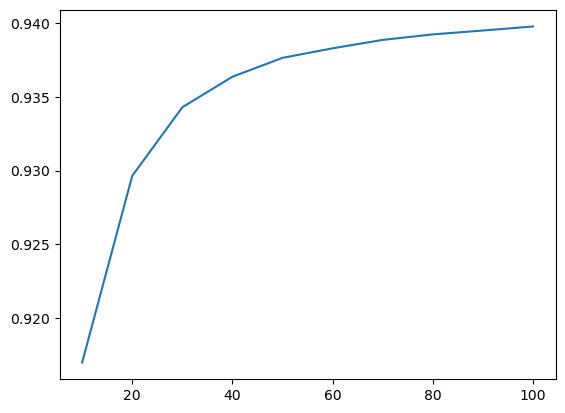

In [32]:
plt.plot(df_scores.n_estimators, df_scores.auc)

In [33]:
scores = []

for d in tqdm([50, 60, 70, 80, 90, 100, 110]):
    for n in range(40, 101, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

 14%|███████████▌                                                                     | 1/7 [12:38<1:15:51, 758.54s/it]

 29%|███████████████████████▏                                                         | 2/7 [25:51<1:04:54, 778.96s/it]

 43%|███████████████████████████████████▌                                               | 3/7 [39:16<52:43, 790.92s/it]

 57%|███████████████████████████████████████████████▍                                   | 4/7 [52:54<40:04, 801.54s/it]

 71%|█████████████████████████████████████████████████████████▊                       | 5/7 [1:06:45<27:04, 812.04s/it]

 86%|█████████████████████████████████████████████████████████████████████▍           | 6/7 [1:20:28<13:35, 815.71s/it]

100%|█████████████████████████████████████████████████████████████████████████████████| 7/7 [1:34:10<00:00, 817.98s/it]

100%|█████████████████████████████████████████████████████████████████████████████████| 7/7 [1:34:10<00:00, 807.27s/it]

In [34]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

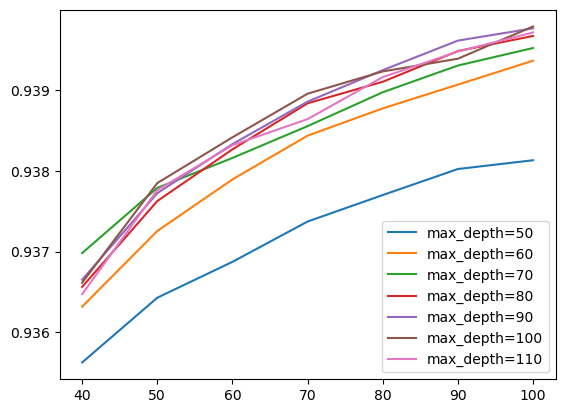

In [35]:
for d in [50, 60, 70, 80, 90, 100, 110]:
    df_subset = df_scores[df_scores.max_depth == d]
    
    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()

`max_depth=80`, `max_depth=90`, `max_depth=100` and `max_depth=110` give similar results. We will use `max_depth=80`.

In [36]:
scores = []

for s in tqdm([1, 3, 5, 10]):
    for n in range(40, 101, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=80,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

  0%|                                                                                            | 0/4 [00:00<?, ?it/s]

 25%|████████████████████▊                                                              | 1/4 [13:37<40:53, 817.91s/it]

 50%|█████████████████████████████████████████▌                                         | 2/4 [25:26<25:06, 753.45s/it]

 75%|██████████████████████████████████████████████████████████████▎                    | 3/4 [36:34<11:54, 714.46s/it]

100%|███████████████████████████████████████████████████████████████████████████████████| 4/4 [46:48<00:00, 674.90s/it]

100%|███████████████████████████████████████████████████████████████████████████████████| 4/4 [46:48<00:00, 702.14s/it]

In [37]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

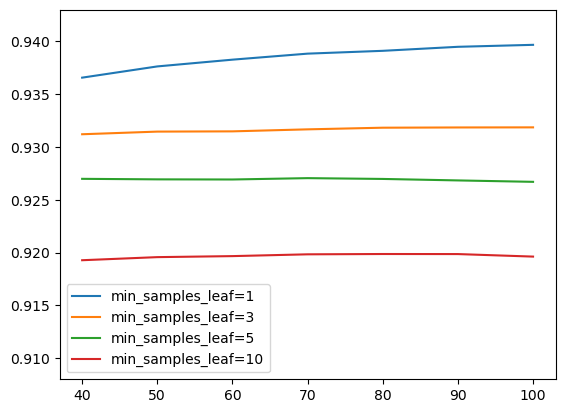

In [38]:
for s in [1, 3, 5, 10]:
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    
    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='min_samples_leaf=%d' % s)

plt.ylim(0.908, 0.943)
plt.legend()

`min_samples_leaf = 1` has the best AUC score.

## XGBoost

Train an XGBoost classifier and tune the `eta` parameter, the maximum depth and the minimum child weight.

In [39]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [40]:
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200)

In [41]:
y_pred = model.predict(dval)

In [42]:
roc_auc_score(y_val, y_pred)

np.float64(0.94553908270228)

In [43]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [44]:
all_scores = []

for ETA in tqdm([0.01, 0.05, 0.1, 0.3, 1]):

    xgb_params = {
        'eta': ETA, 
        'max_depth': 6,
        'min_child_weight': 10,
        
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    scores = {}

    model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                      verbose_eval=False,
                      evals=watchlist,
                      evals_result=scores                      
                     )

    all_scores.append((ETA,scores['val']['auc']))

  0%|                                                                                            | 0/5 [00:00<?, ?it/s]

 20%|████████████████▊                                                                   | 1/5 [00:32<02:09, 32.30s/it]

 40%|█████████████████████████████████▌                                                  | 2/5 [00:59<01:27, 29.30s/it]

 60%|██████████████████████████████████████████████████▍                                 | 3/5 [01:24<00:54, 27.19s/it]

 80%|███████████████████████████████████████████████████████████████████▏                | 4/5 [01:45<00:25, 25.05s/it]

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [02:06<00:00, 23.60s/it]

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [02:06<00:00, 25.39s/it]

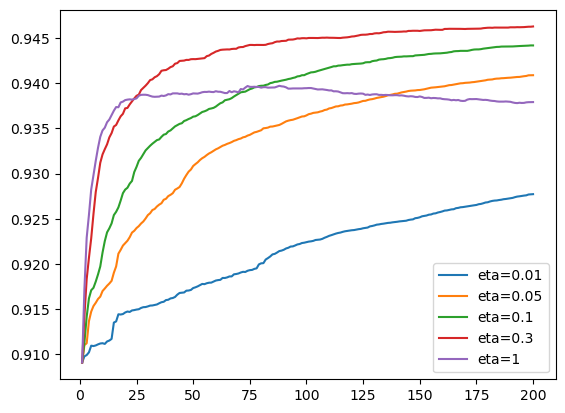

In [45]:
for eta, auc in all_scores:
    plt.plot(range(1, len(auc) + 1), auc, label=f'eta={eta}')

plt.legend()

The model with `eta = 0.3` is the one with the best score.

In [46]:
all_scores = []

for MAX_DEPTH in tqdm([3,4,6,8,10]):

    xgb_params = {
        'eta': 0.3, 
        'max_depth': MAX_DEPTH,
        'min_child_weight': 10,
        
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    scores = {}

    model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                      verbose_eval=False,
                      evals=watchlist,
                      evals_result=scores                      
                     )

    all_scores.append((MAX_DEPTH,scores['val']['auc']))

  0%|                                                                                            | 0/5 [00:00<?, ?it/s]

 20%|████████████████▊                                                                   | 1/5 [00:18<01:13, 18.50s/it]

 40%|█████████████████████████████████▌                                                  | 2/5 [00:38<00:58, 19.40s/it]

 60%|██████████████████████████████████████████████████▍                                 | 3/5 [01:00<00:40, 20.40s/it]

 80%|███████████████████████████████████████████████████████████████████▏                | 4/5 [01:22<00:21, 21.34s/it]

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [01:47<00:00, 22.43s/it]

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [01:47<00:00, 21.45s/it]

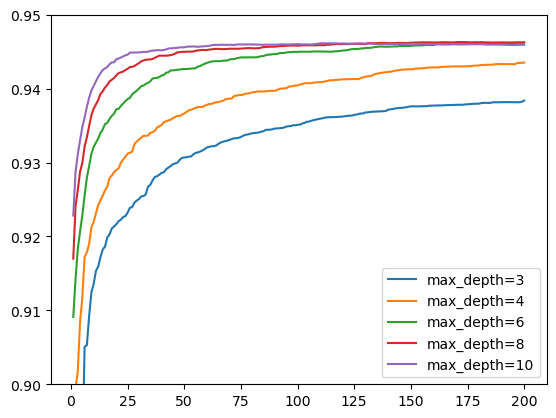

In [47]:
for m_d, auc in all_scores:
    plt.plot(range(1, len(auc) + 1), auc, label=f'max_depth={m_d}')

plt.ylim(0.9, 0.95)
plt.legend()

`max_depth=8` and `max_depth=10` give similar results. We will use `max_depth=8`.

In [48]:
all_scores = []

for MIN_CHILD_WEIGHT in tqdm([1, 10, 20, 30]):

    xgb_params = {
        'eta': 0.3, 
        'max_depth': 8,
        'min_child_weight': MIN_CHILD_WEIGHT,
        
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    scores = {}

    model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                      verbose_eval=False,
                      evals=watchlist,
                      evals_result=scores                      
                     )

    all_scores.append((MIN_CHILD_WEIGHT,scores['val']['auc']))

  0%|                                                                                            | 0/4 [00:00<?, ?it/s]

 25%|█████████████████████                                                               | 1/4 [00:22<01:08, 22.71s/it]

 50%|██████████████████████████████████████████                                          | 2/4 [00:45<00:45, 22.86s/it]

 75%|███████████████████████████████████████████████████████████████                     | 3/4 [01:08<00:22, 22.98s/it]

100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [01:32<00:00, 23.14s/it]

100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [01:32<00:00, 23.05s/it]

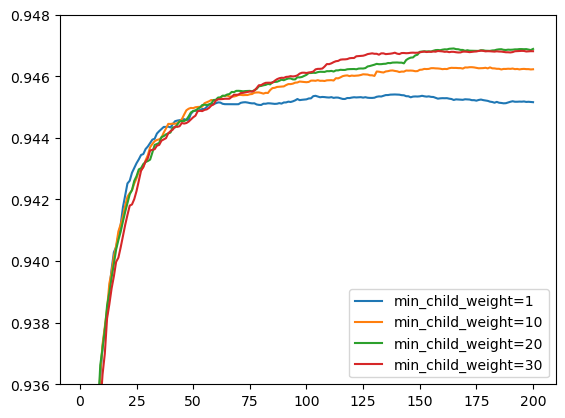

In [49]:
for m_c_w, auc in all_scores:
    plt.plot(range(1, len(auc) + 1), auc, label=f'min_child_weight={m_c_w}')

plt.ylim(0.936, 0.948)
plt.legend()

`min_child_weight = 20` and `min_child_weight = 30` have similar scores. We will use `min_child_weight = 20`.

## Selecting the Best Model

Compare the three tuned models and select the one with the best ROC-AUC score on the validation dataset.

In [50]:
scores = []

In [51]:
dt = DecisionTreeClassifier(max_depth=22, min_samples_leaf=100)
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=22, min_samples_leaf=100)

In [52]:
y_pred = dt.predict_proba(X_val)[:, 1]
scores.append(('DecisionTreeClassifier',roc_auc_score(y_val, y_pred)))
roc_auc_score(y_val, y_pred)

np.float64(0.9288750254178837)

In [53]:
rf = RandomForestClassifier(n_estimators=100,
                            max_depth=80,
                            min_samples_leaf=1,
                            random_state=1)
rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=80, random_state=1)

In [54]:
y_pred = rf.predict_proba(X_val)[:, 1]
scores.append(('RandomForestClassifier',roc_auc_score(y_val, y_pred)))
roc_auc_score(y_val, y_pred)

np.float64(0.9396709734382729)

In [55]:
xgb_params = {
        'eta': 0.3, 
        'max_depth': 8,
        'min_child_weight': 20,
        
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

model = xgb.train(xgb_params, dtrain, num_boost_round=200)

In [56]:
y_pred = model.predict(dval)
scores.append(('XGBoost',roc_auc_score(y_val, y_pred)))
roc_auc_score(y_val, y_pred)

np.float64(0.9468875891948665)

In [57]:
columns = ['Model', 'ROC-AUC']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores

,Model,ROC-AUC
0,DecisionTreeClassifier,0.928875
1,RandomForestClassifier,0.939671
2,XGBoost,0.946888


The best model is the XGBoost, since it is the one with the best ROC-AUC score. Its validation ROC-AUC is 0.947.

## Train the best model and make predictions

Train the best model (the XGBoost classifier) on the full training dataset and compute the predictions on the test dataset.

In [58]:
df_full_train = df.reset_index(drop=True)

In [59]:
y_full_train = df['pitnextlap'].astype('int').values

In [60]:
del df_full_train['pitnextlap']

In [61]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

In [62]:
df_test = pd.read_csv('test.csv')
len(df_test)

188165

In [63]:
df_test.columns = df_test.columns.str.lower().str.replace(' ', '_')

string_columns = list(df_test.dtypes[df_test.dtypes == 'object'].index)

for col in string_columns:
    df_test[col] = df_test[col].str.lower().str.replace(' ', '_')

del df_test['id']

In [64]:
dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [65]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
dtest = xgb.DMatrix(X_test, feature_names=features)

In [66]:
xgb_params = {
        'eta': 0.3, 
        'max_depth': 8,
        'min_child_weight': 20,
        
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

model = xgb.train(xgb_params, dtrain, num_boost_round=200)

In [67]:
importances = model.get_score(importance_type='gain')

columns = ['Feature', 'Importance']
df_importances = pd.DataFrame(importances.items(), columns=columns)

df_importances = df_importances.sort_values(by='Importance',ascending=False)

df_importances.head(5)

,Feature,Importance
355,stint,406.417969
357,year,347.667267
3,compound=soft,173.520340
352,race=são_paulo_grand_prix,100.533936
344,race=mexico_city_grand_prix,72.528671


The most important features according to XGBoost's gain-based importance are `stint`, `year`, `compound=soft`, `race=são_paulo_grand_prix` and `race=mexico_city_grand_prix`. Gain measures the improvement in the model's objective function brought by splits using a given feature. These results suggest that tyre stint information, the season and race-specific effects are particularly useful for the predictions.

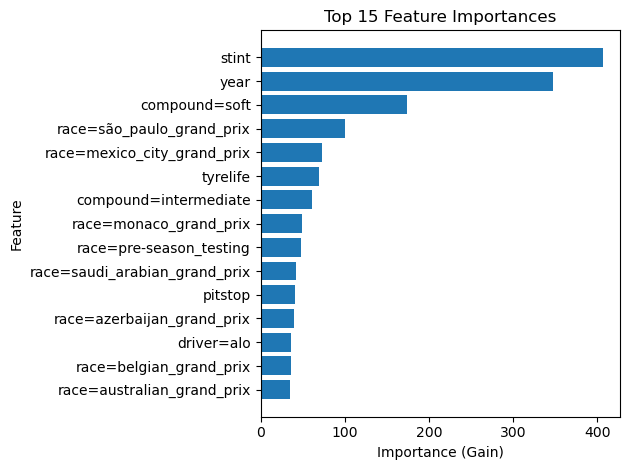

In [68]:
plt.barh(
    df_importances['Feature'][:15].iloc[::-1],
    df_importances['Importance'][:15].iloc[::-1]
)

plt.title('Top 15 Feature Importances')
plt.xlabel('Importance (Gain)')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [69]:
y_pred = model.predict(dtest)

In [70]:
y_pred

array([0.00248796, 0.00609724, 0.00160082, ..., 0.8354512 , 0.8560717 ,
       0.01176464], shape=(188165,), dtype=float32)